# Replication of *The Probability of Backtest Overfitting*

**Assumption: `demo_experiment` has already run successfully, including plotting.**
This walkthrough reads the saved results for **seed 42**. Select the project's
`.venv` kernel and run the cells in order; the experiment is not rerun.

The project examines the central finding of Bailey, Borwein, López de Prado and
Zhu: a strong backtest can reflect fitted noise, while a real seasonal signal
can make strategy selection more reliable out of sample. As in the paper, we
compare monthly trading rules on a random walk without a signal and a random
walk with an added monthly effect.

## 1. Experiment setup

CSCV selects the highest-Sharpe strategy on each training half and evaluates it
on the complementary testing half. PBO is the fraction of splits where the
training winner ranks below the testing median. The settings below come from
the saved experiment, rather than the current configuration file.

In [1]:
import json
from math import comb

import pandas as pd
from IPython.display import Image, Markdown, display
from backtest_overfitting import paths

EXPERIMENT = "demo_experiment"
SEED = 42

result_dir = paths.result_dir(EXPERIMENT, SEED)
tables_dir = paths.tables_dir(EXPERIMENT, SEED)
figures_dir = paths.figures_dir(EXPERIMENT, SEED)
metadata_file = result_dir / "experiment.json"
if not metadata_file.is_file():
    raise FileNotFoundError("Run the configured demo first, or select an existing experiment and seed.")

metadata = json.loads(metadata_file.read_text())
summary = pd.DataFrame({
    name: pd.read_csv(tables_dir / name / "sharpe" / "summary.csv").iloc[0]
    for name in ("no_signal", "seasonal")
}).T
pooled = pd.read_csv(tables_dir / "pooled_dominance_summary.csv").set_index("scenario")

print(f"Experiment: {EXPERIMENT}; seed: {metadata['seed']}")
print(f"Observations: {metadata['T']:,}; blocks: {metadata['S']}; "
      f"CSCV combinations: {comb(metadata['S'], metadata['S'] // 2):,}")
for name in summary.index:
    print(f"{name.replace('_', ' ').capitalize()}: "
          f"{int(summary.loc[name, 'n_strategies']):,} eligible strategies")

Experiment: demo_experiment; seed: 42
Observations: 1,000; blocks: 10; CSCV combinations: 252
No signal: 7,600 eligible strategies
Seasonal: 7,600 eligible strategies


## 2. Compare the results with the paper

The paper reports PBO of 55% without a signal and 13% with a seasonal signal.
The corresponding frequencies of negative OOS Sharpe are 53% and 13%
([Figures 7–12](https://www.davidhbailey.com/dhbpapers/backtest-prob.pdf)).
The replication columns below are loaded directly from the saved summaries.

In [2]:
comparison = pd.DataFrame({
    "Paper: no signal": [0.55, 0.53],
    "Replication: no signal": [summary.loc["no_signal", "pbo"],
                                summary.loc["no_signal", "probability_of_loss"]],
    "Paper: seasonal": [0.13, 0.13],
    "Replication: seasonal": [summary.loc["seasonal", "pbo"],
                               summary.loc["seasonal", "probability_of_loss"]],
}, index=["PBO", "Negative OOS Sharpe"])
display(comparison.style.format("{:.2%}"))

,Paper: no signal,Replication: no signal,Paper: seasonal,Replication: seasonal
PBO,55.00%,70.24%,13.00%,5.16%
Negative OOS Sharpe,53.00%,68.25%,13.00%,5.56%


## 3. Compare the plot patterns

The saved figure puts the no-signal results on the left and seasonal results on
the right. It shows the same qualitative contrast discussed in the paper:

- **Degradation (Figures 7 and 11):** the no-signal scatter contains many negative
  testing scores; the seasonal scatter lies mostly above zero. Both fitted
  slopes are negative.
- **Rank logits (Figures 8 and 12):** most no-signal logits are negative, while
  most seasonal logits are positive, explaining the difference in PBO.
- **Cumulative distributions (Figures 9 and 13):** seasonal winners shift toward
  better testing scores relative to the pooled strategies. No-signal winners
  show no dominance.

These are similarities in direction and interpretation, not identical scatter
patterns, histogram peaks, or CDF shapes.

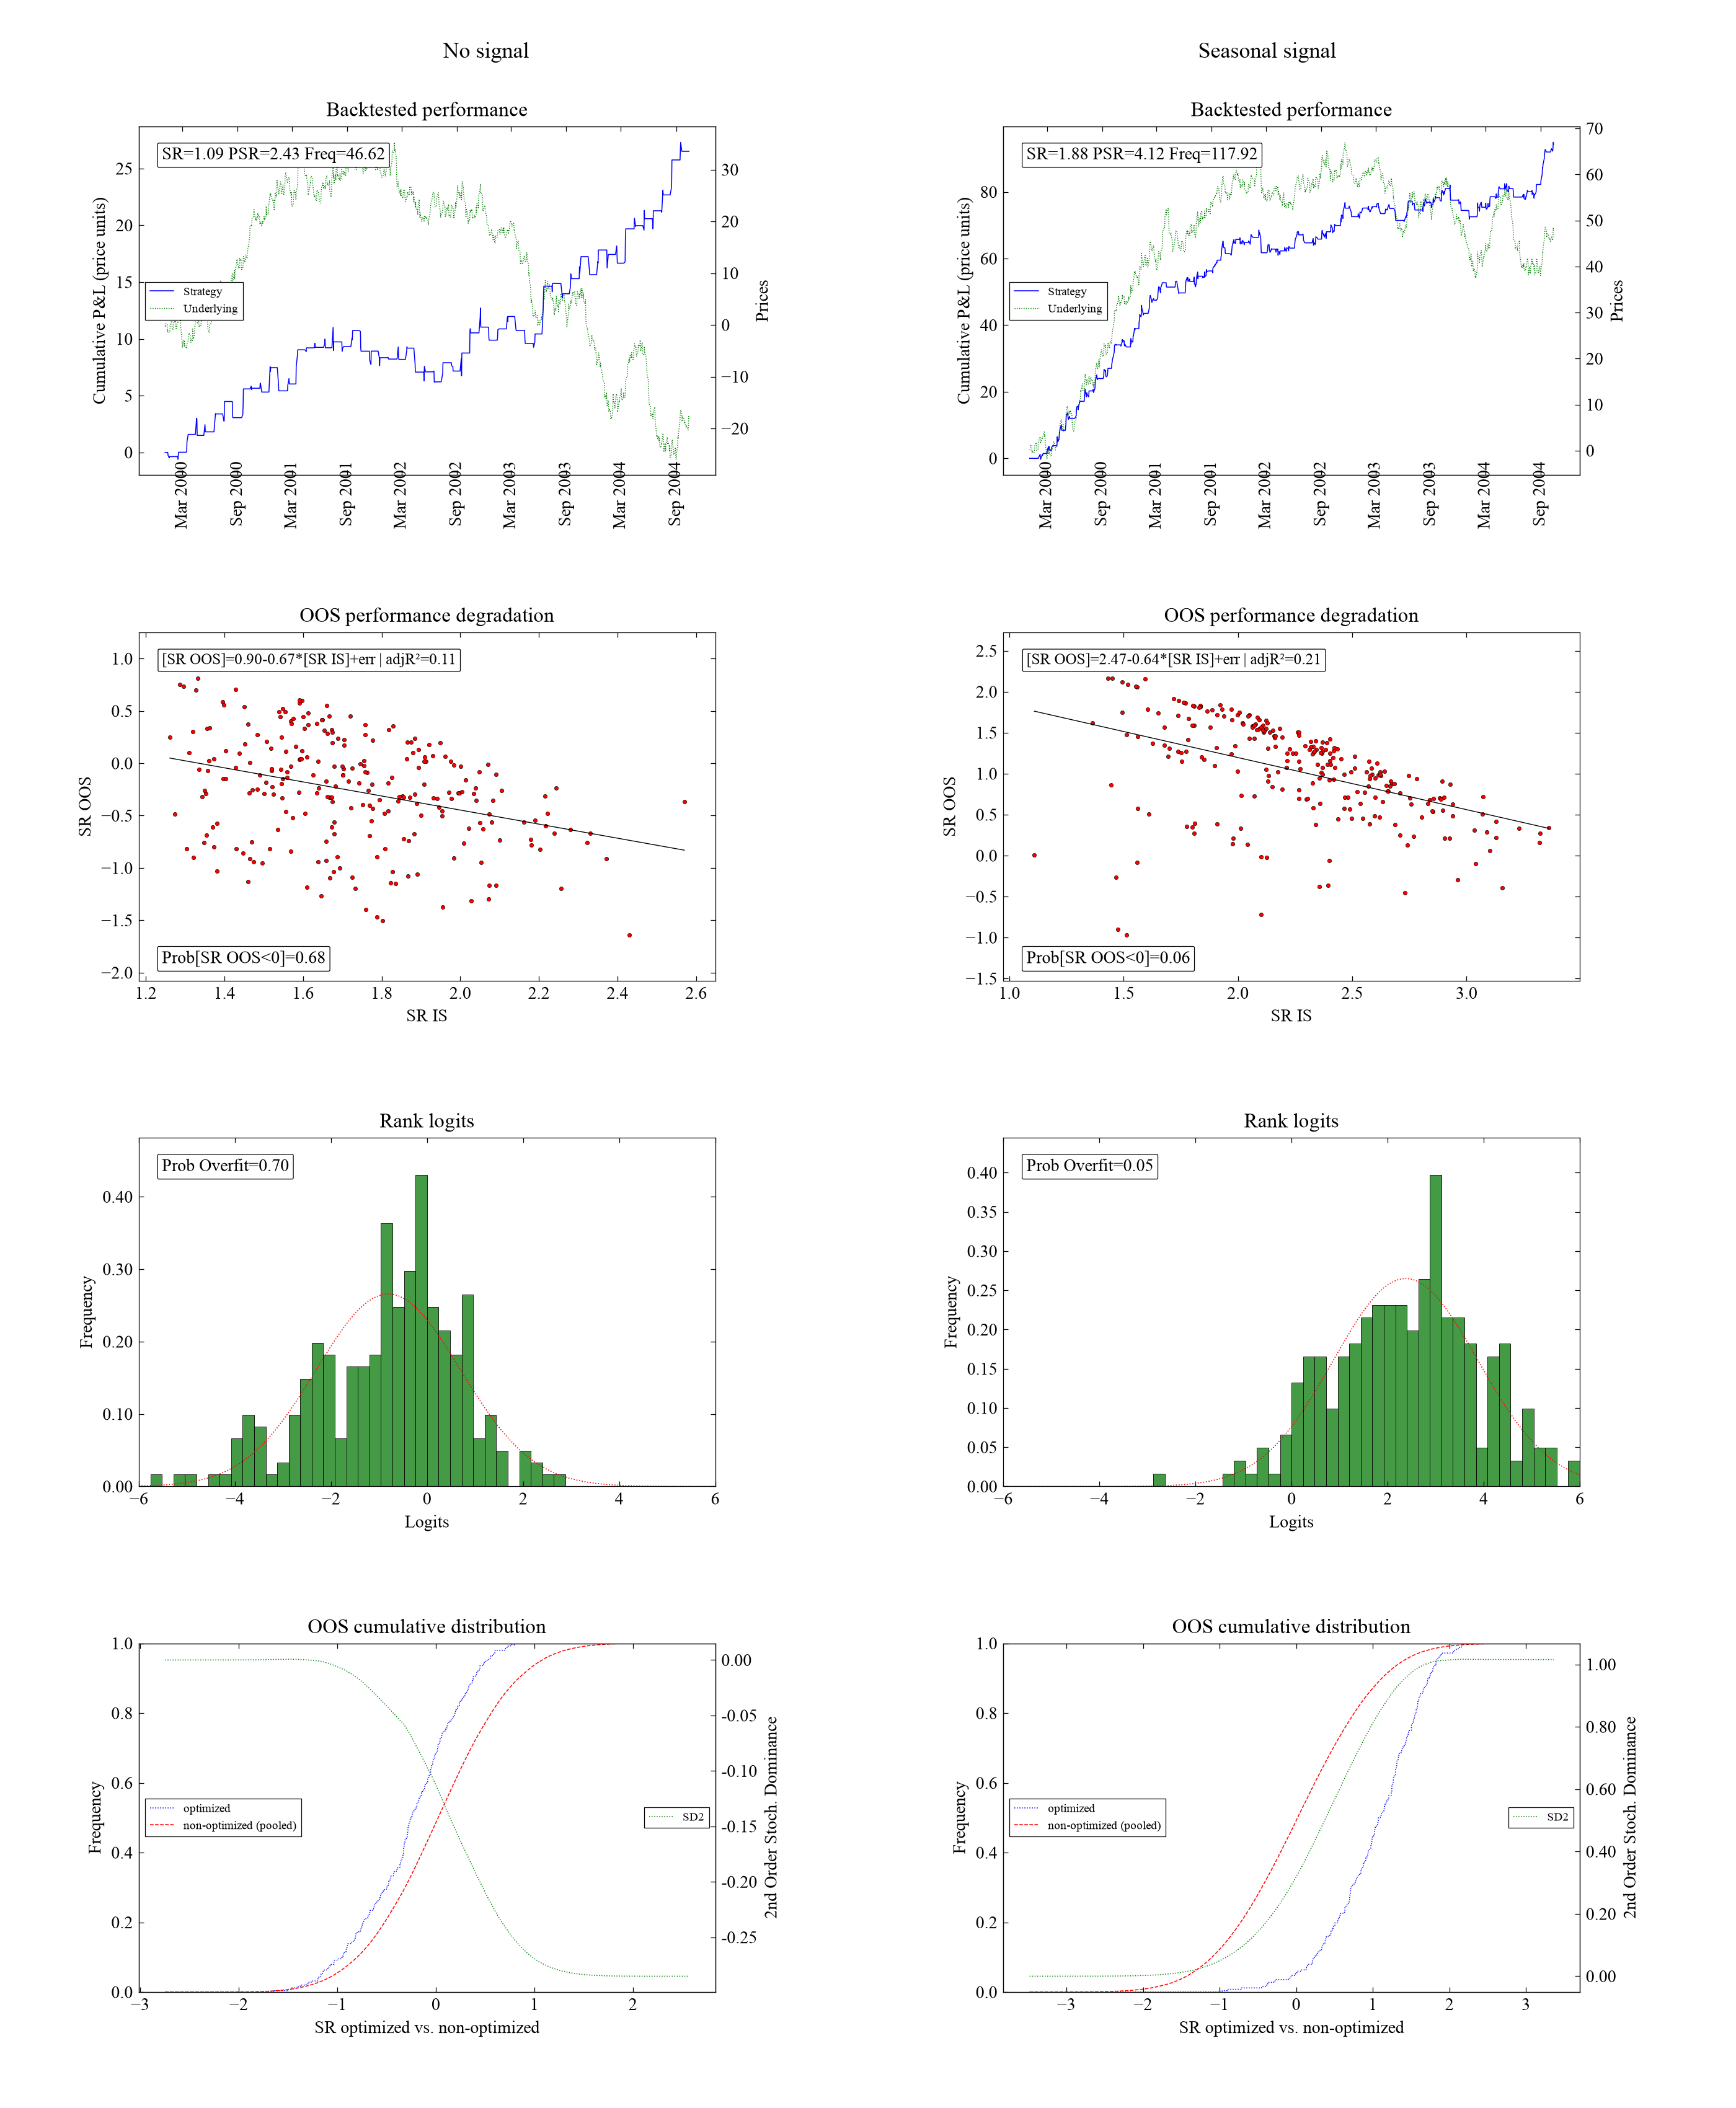

In [3]:
display(Image(filename=str(figures_dir / "comparison.png"), width=1050))

## 4. Interpretation

The saved run reproduces the paper's contrast: selecting strategies on noise
frequently produces below-median or negative testing performance, whereas both
frequencies fall sharply with a seasonal signal. The following diagnostics
summarize the plotted regression and dominance results. Dominance here uses the
**pooled-strategy benchmark**, matching the plotted CDFs.

In [4]:
diagnostics = pd.DataFrame({
    "Degradation slope": summary["degradation_slope"].astype(float),
    "First-order dominance": pooled["first_order_dominance_vs_pooled"],
    "Second-order dominance": pooled["second_order_dominance_vs_pooled"],
}).rename(index={"no_signal": "No signal", "seasonal": "Seasonal signal"})
display(diagnostics.style.format({"Degradation slope": "{:.3f}"}))

,Degradation slope,First-order dominance,Second-order dominance
No signal,-0.672,False,False
Seasonal signal,-0.636,False,True


**Reference:** Bailey et al., *The Probability of Backtest Overfitting*, seasonal
examples ([paper](https://www.davidhbailey.com/dhbpapers/backtest-prob.pdf);
[SSRN record](https://papers.ssrn.com/sol3/papers.cfm?abstract_id=2326253)).

**Saved Results:** `results/replication/demo_experiment/seed_42/` contains
`experiment.json`, the scenario summaries under `tables/`,
`tables/pooled_dominance_summary.csv`, and `figures/comparison.pdf`.